# BanglaT5 Fine-tuning — Abstractive Summarization

---

## Section 1: Install & Imports

In [ ]:
!pip install transformers datasets evaluate rouge_score sentencepiece bert-score nltk -q

import os, json, gc, time
import numpy as np
import pandas as pd
import torch
import re
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from transformers import (
    AutoTokenizer, AutoModelForSeq2SeqLM, Seq2SeqTrainer,
    Seq2SeqTrainingArguments, DataCollatorForSeq2Seq,
    TrainerCallback, EarlyStoppingCallback
)
from transformers.trainer_utils import get_last_checkpoint
from datasets import Dataset, DatasetDict
from bert_score import score as bert_score
from nltk.translate.bleu_score import corpus_bleu, sentence_bleu, SmoothingFunction
import nltk
import evaluate

nltk.download('punkt', quiet=True)
os.environ["WANDB_DISABLED"] = "true"
sns.set_theme(style='darkgrid')

os.environ['CUDA_VISIBLE_DEVICES'] = '0'  #dont use gpu 0 

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

Device: cuda
GPU: NVIDIA RTX A6000
VRAM: 51.5 GB


## Section 2: Configuration

In [18]:
CONFIG = {
    'data_path'                  : 'D:/student_2k20/2007058/Summar/extractive/bb-lexr/bn_summaries.jsonl',
    'text_col'                   : 'content',
    'summary_col'                : 'summarized',
    'category_col'               : 'Category',
    'subset_start'               : 0,
    'subset_size'                : 120000,
    'model_name'                 : 'csebuetnlp/banglat5',
    'max_input_len'              : 512,
    'max_target_len'             : 128,
    'train_batch'                : 16,
    'eval_batch'                 : 16,
    'gradient_accumulation_steps': 2,
    'epochs'                     : 10,
    'lr'                         : 2e-5,
    'weight_decay'               : 0.01,
    'output_dir'                 : './banglat5_results',
    'model_save_dir'             : './fine_tuned_banglat5',
    'seed'                       : 42,

    'save_total_limit'           : 3,
    'checkpoints_per_epoch'      : 4,
    'early_stopping_patience'    : 2,

    'eval_sample'                : 500,
}

torch.manual_seed(CONFIG['seed'])
np.random.seed(CONFIG['seed'])
Path(CONFIG['output_dir']).mkdir(exist_ok=True)
Path(CONFIG['model_save_dir']).mkdir(exist_ok=True)

## Section 3: Load Dataset

In [19]:
df_full = pd.read_json(CONFIG['data_path'], lines=True)
print(f'Full dataset: {len(df_full):,} rows')
print(f'Columns: {df_full.columns.tolist()}')

start = CONFIG['subset_start']
end   = start + CONFIG['subset_size']
df    = df_full.iloc[start:end].copy()
df    = df.dropna(subset=[CONFIG['text_col'], CONFIG['summary_col']]).reset_index(drop=True)

print(f'Working subset ({start} to {end}): {len(df):,} rows')
df[[CONFIG['category_col'], CONFIG['text_col'], CONFIG['summary_col']]].head(3)

Full dataset: 116,505 rows
Columns: ['data_id', 'Category', 'content', 'summarized']
Working subset (0 to 120000): 116,505 rows


,Category,content,summarized
0,অন্যান্য,"শাওমি মি মিক্স আলফা, এর দাম গ্যালাক্সি ফোল্ড থ...","শাওমি মি মিক্স আলফা, এর দাম গ্যালাক্সি ফোল্ড থ..."
1,ফিচার,যে কোনো একটি মেয়ের বাবা অথবা মা মারা গেছে কিংব...,ইতিমধ্যেই তারা বেশকিছু কর্মকাণ্ড হাতে নিয়েছে ন...
2,জাতীয়,জি টু জি দুই দেশের সরকারের মধ্যে চুক্তির আওতায়...,জি টু জি দুই দেশের সরকারের মধ্যে চুক্তির আওতায়...


## Section 4: Dataset Visualization

In [20]:
import matplotlib
import matplotlib.font_manager as fm

font_path = r"D:/student_2k20/2007058/Summar/extractive/bb-lexr/kalpurush.ttf"

fm.fontManager.addfont(font_path)
prop = fm.FontProperties(fname=font_path)
matplotlib.rcParams['font.family'] = prop.get_name()
print(f"Bangla font set: {prop.get_name()}")

Bangla font set: Noto Sans Bengali


findfont: Failed to find font weight bold, now using 400.


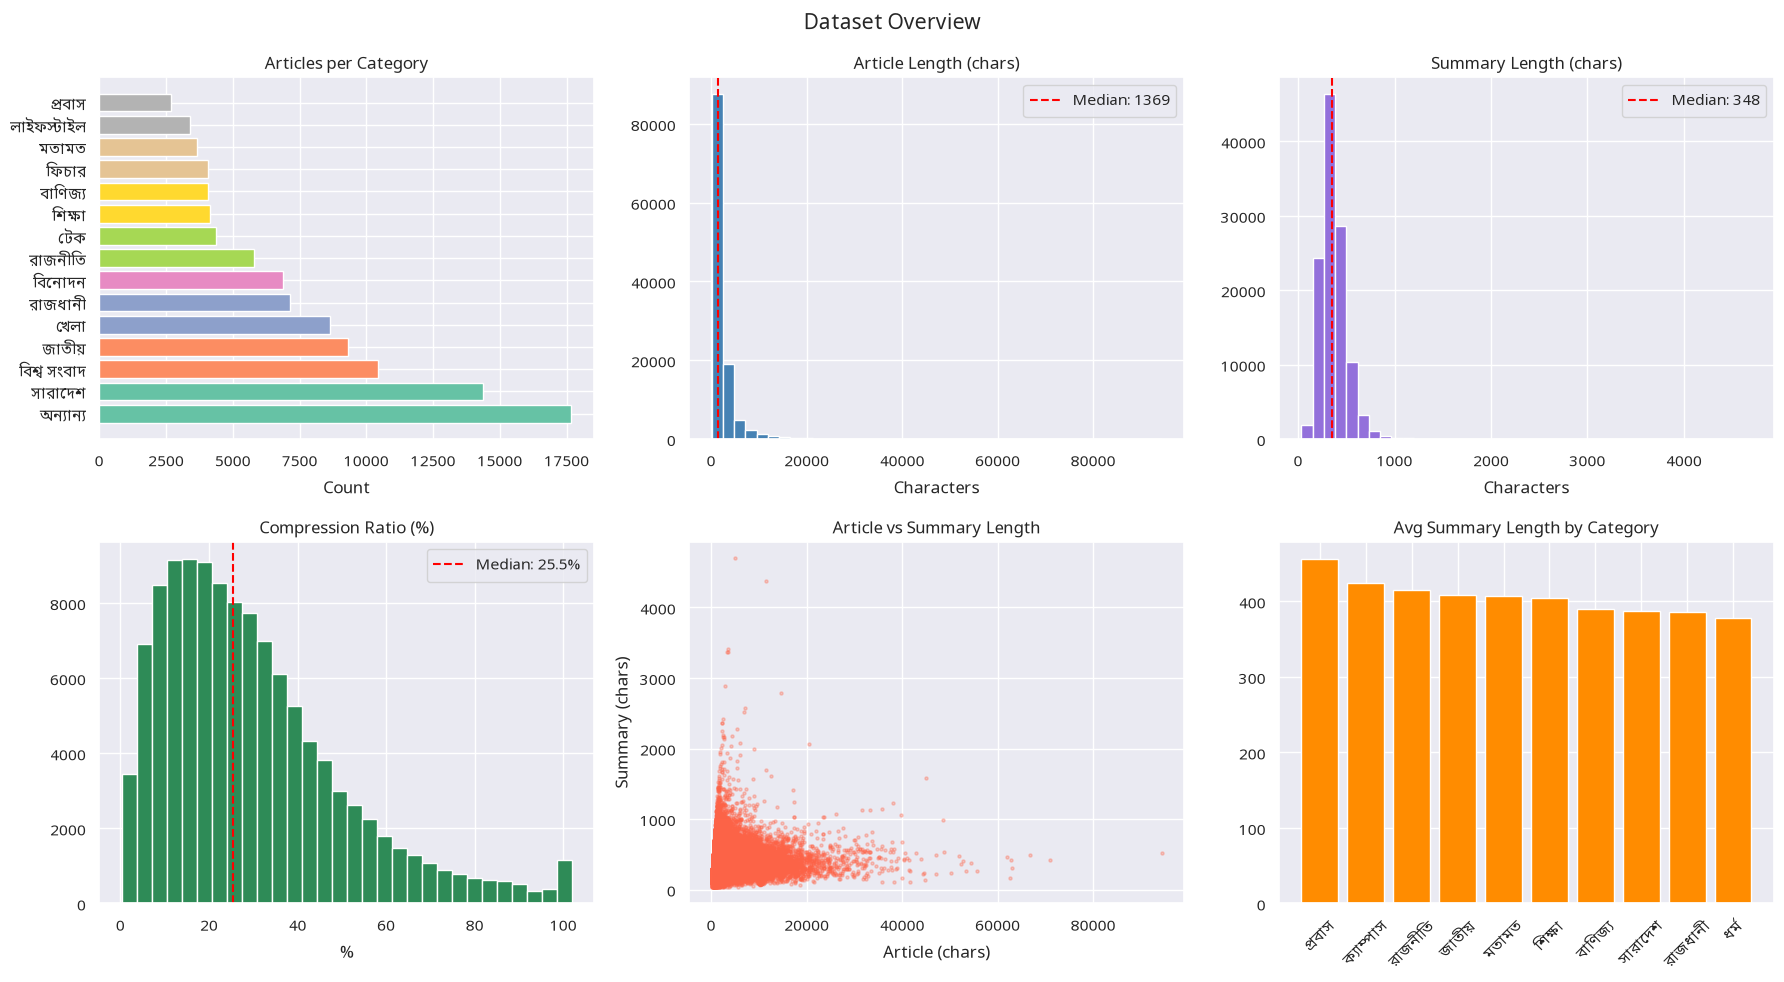

       input_len  summary_len  compression
count   116505.0     116505.0     116505.0
mean      2214.6        367.3         29.8
std       2803.2        139.7         20.6
min         95.0         35.0          0.3
25%        876.0        276.0         14.3
50%       1369.0        348.0         25.5
75%       2443.0        433.0         39.9
max      94331.0       4700.0        101.9


In [21]:
df['input_len']   = df[CONFIG['text_col']].str.len()
df['summary_len'] = df[CONFIG['summary_col']].str.len()
df['compression'] = (df['summary_len'] / df['input_len'] * 100).round(1)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Dataset Overview', fontsize=15, fontweight='bold')

cat_counts = df[CONFIG['category_col']].value_counts().head(15)
axes[0,0].barh(cat_counts.index, cat_counts.values, color=plt.cm.Set2(np.linspace(0,1,len(cat_counts))))
axes[0,0].set_title('Articles per Category')
axes[0,0].set_xlabel('Count')

axes[0,1].hist(df['input_len'], bins=40, color='steelblue', edgecolor='white')
axes[0,1].axvline(df['input_len'].median(), color='red', linestyle='--', label=f'Median: {df["input_len"].median():.0f}')
axes[0,1].set_title('Article Length (chars)')
axes[0,1].set_xlabel('Characters')
axes[0,1].legend()

axes[0,2].hist(df['summary_len'], bins=40, color='mediumpurple', edgecolor='white')
axes[0,2].axvline(df['summary_len'].median(), color='red', linestyle='--', label=f'Median: {df["summary_len"].median():.0f}')
axes[0,2].set_title('Summary Length (chars)')
axes[0,2].set_xlabel('Characters')
axes[0,2].legend()

axes[1,0].hist(df['compression'], bins=30, color='seagreen', edgecolor='white')
axes[1,0].axvline(df['compression'].median(), color='red', linestyle='--', label=f'Median: {df["compression"].median():.1f}%')
axes[1,0].set_title('Compression Ratio (%)')
axes[1,0].set_xlabel('%')
axes[1,0].legend()

axes[1,1].scatter(df['input_len'], df['summary_len'], alpha=0.3, s=5, color='tomato')
axes[1,1].set_title('Article vs Summary Length')
axes[1,1].set_xlabel('Article (chars)')
axes[1,1].set_ylabel('Summary (chars)')

avg_sumlen = df.groupby(CONFIG['category_col'])['summary_len'].mean().sort_values(ascending=False).head(10)
axes[1,2].bar(avg_sumlen.index, avg_sumlen.values, color='darkorange')
axes[1,2].set_title('Avg Summary Length by Category')
axes[1,2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(f"{CONFIG['output_dir']}/dataset_overview.png", dpi=150, bbox_inches='tight')
plt.show()
print(df[['input_len','summary_len','compression']].describe().round(1))

## Section 5: Prepare Data for T5

In [22]:
df['model_input'] = df.apply(
    lambda r: f"সারসংক্ষেপ করুন [{r[CONFIG['category_col']]}]: {r[CONFIG['text_col']]}",
    axis=1
)

train_df, temp_df = train_test_split(df, test_size=0.2, random_state=CONFIG['seed'])
val_df, test_df   = train_test_split(temp_df, test_size=0.5, random_state=CONFIG['seed'])

print(f'Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}')

train_dataset = Dataset.from_pandas(train_df[['model_input', CONFIG['summary_col']]].rename(columns={'model_input':'text', CONFIG['summary_col']:'summary'}))
val_dataset   = Dataset.from_pandas(val_df[['model_input',   CONFIG['summary_col']]].rename(columns={'model_input':'text', CONFIG['summary_col']:'summary'}))
test_dataset  = Dataset.from_pandas(test_df[['model_input',  CONFIG['summary_col']]].rename(columns={'model_input':'text', CONFIG['summary_col']:'summary'}))

dataset_dict = DatasetDict({'train': train_dataset, 'val': val_dataset, 'test': test_dataset})
print(dataset_dict)

Train: 93,204 | Val: 11,650 | Test: 11,651
DatasetDict({
    train: Dataset({
        features: ['text', 'summary', '__index_level_0__'],
        num_rows: 93204
    })
    val: Dataset({
        features: ['text', 'summary', '__index_level_0__'],
        num_rows: 11650
    })
    test: Dataset({
        features: ['text', 'summary', '__index_level_0__'],
        num_rows: 11651
    })
})


## Section 6: Load Model & Tokenizer

In [23]:
torch.cuda.empty_cache()
gc.collect()

tokenizer = AutoTokenizer.from_pretrained(CONFIG['model_name'])
model     = AutoModelForSeq2SeqLM.from_pretrained(CONFIG['model_name']).to(DEVICE)

print(f'Model loaded on {DEVICE}')
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')

Loading weights: 100%|██████████| 284/284 [00:00<00:00, 25797.69it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Model loaded on cuda
Parameters: 247,577,856


## Section 7: Tokenization

In [24]:
def preprocess(examples):
    inputs  = tokenizer(examples['text'],    max_length=CONFIG['max_input_len'],  truncation=True, padding='max_length')
    targets = tokenizer(examples['summary'], max_length=CONFIG['max_target_len'], truncation=True, padding='max_length')

    labels = [
        [-100 if t == tokenizer.pad_token_id else t for t in label]
        for label in targets['input_ids']
    ]
    inputs['labels'] = labels
    return inputs

tokenized = dataset_dict.map(preprocess, batched=True, remove_columns=['text', 'summary'])
print('Tokenization done')
print(tokenized)

Map: 100%|██████████| 11651/11651 [00:22<00:00, 520.64 examples/s]

Tokenization done
DatasetDict({
    train: Dataset({
        features: ['__index_level_0__', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 93204
    })
    val: Dataset({
        features: ['__index_level_0__', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 11650
    })
    test: Dataset({
        features: ['__index_level_0__', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 11651
    })
})


## Section 8: Training

Resumable

In [25]:
rouge = evaluate.load('rouge')

def bangla_tokenize(text):
    text = re.sub(r'[।!?,]', ' ', text)
    return [t for t in text.split() if t]

def compute_metrics(eval_pred):
    preds, labels = eval_pred
    preds  = np.where(preds  != -100, preds,  tokenizer.pad_token_id)
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_preds  = tokenizer.batch_decode(preds,  skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    result = rouge.compute(
        predictions=decoded_preds,
        references=decoded_labels,
        tokenizer=bangla_tokenize
    )
    return {k: round(v, 4) for k, v in result.items()}

training_args = Seq2SeqTrainingArguments(
    output_dir                   = CONFIG['output_dir'],
    eval_strategy                = 'epoch',
    save_strategy                = 'epoch',
    save_total_limit             = CONFIG['save_total_limit'],
    learning_rate                = CONFIG['lr'],
    per_device_train_batch_size  = CONFIG['train_batch'],
    per_device_eval_batch_size   = CONFIG['eval_batch'],
    gradient_accumulation_steps  = CONFIG['gradient_accumulation_steps'],
    num_train_epochs             = CONFIG['epochs'],
    weight_decay                 = CONFIG['weight_decay'],
    predict_with_generate        = True,
    generation_max_length        = CONFIG['max_target_len'],
    load_best_model_at_end       = True,
    metric_for_best_model        = 'rougeL',
    greater_is_better            = True,
    fp16                         = False,
    bf16                         = torch.cuda.is_bf16_supported(),
    logging_steps                = 100,
    report_to                    = 'none',
    seed                         = CONFIG['seed'],
)

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model, padding=True)


class PeriodicCheckpointCallback(TrainerCallback):
    """Forces extra checkpoints mid-epoch so a crash never loses more than a fraction of an epoch."""
    def __init__(self, every_n_steps):
        self.every_n_steps = every_n_steps

    def on_step_end(self, args, state, control, **kwargs):
        if self.every_n_steps and state.global_step > 0 and state.global_step % self.every_n_steps == 0:
            control.should_save = True
        return control


class DetailedEpochCallback(TrainerCallback):
    """Prints a detailed summary (loss, ROUGE, timing, ETA) at the end of every epoch."""
    def __init__(self, total_epochs):
        self.total_epochs = total_epochs
        self.epoch_start_time = None

    def on_epoch_begin(self, args, state, control, **kwargs):
        self.epoch_start_time = time.time()

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        if metrics is None:
            return
        elapsed   = time.time() - self.epoch_start_time if self.epoch_start_time else 0
        epoch     = int(round(state.epoch))
        remaining = max(self.total_epochs - epoch, 0)
        eta       = elapsed * remaining

        train_losses    = [x['loss'] for x in state.log_history if 'loss' in x and 'eval_loss' not in x]
        last_train_loss = train_losses[-1] if train_losses else float('nan')

        print(f'\n{"="*62}')
        print(f'Epoch {epoch}/{self.total_epochs}  —  {elapsed/60:.1f} min')
        print(f'  Train loss  : {last_train_loss:.4f}')
        print(f"  Eval loss   : {metrics.get('eval_loss', float('nan')):.4f}")
        print(f"  ROUGE-1     : {metrics.get('eval_rouge1', 0):.4f}")
        print(f"  ROUGE-2     : {metrics.get('eval_rouge2', 0):.4f}")
        print(f"  ROUGE-L     : {metrics.get('eval_rougeL', 0):.4f}")
        print(f'  ETA remaining: {eta/60:.1f} min ({remaining} epoch(s) left)')
        print(f'{"="*62}\n')


trainer = Seq2SeqTrainer(
    model            = model,
    args             = training_args,
    train_dataset    = tokenized['train'],
    eval_dataset     = tokenized['val'],
    processing_class = tokenizer,
    data_collator    = data_collator,
    compute_metrics  = compute_metrics,
    callbacks        = [EarlyStoppingCallback(early_stopping_patience=CONFIG['early_stopping_patience'])],
)

steps_per_epoch    = int(np.ceil(len(tokenized['train']) / (CONFIG['train_batch'] * CONFIG['gradient_accumulation_steps'])))
save_every_n_steps = max(50, steps_per_epoch // CONFIG['checkpoints_per_epoch'])
print(f'Steps per epoch: {steps_per_epoch}  |  extra checkpoint every {save_every_n_steps} steps')

trainer.add_callback(PeriodicCheckpointCallback(save_every_n_steps))
trainer.add_callback(DetailedEpochCallback(CONFIG['epochs']))

last_checkpoint = get_last_checkpoint(CONFIG['output_dir']) if os.path.isdir(CONFIG['output_dir']) else None
print(f' Resuming from: {last_checkpoint}' if last_checkpoint else ' Starting training from scratch.')

trainer.train(resume_from_checkpoint=last_checkpoint)

Steps per epoch: 2913  |  extra checkpoint every 728 steps
 Resuming from: ./banglat5_results\checkpoint-14565


[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum
6,1.162280,0.453878,0.500300,0.439600,0.474700,0.474700
7,1.191171,0.432489,0.507500,0.447500,0.483100,0.483100
8,1.129606,0.414884,0.525800,0.467800,0.502700,0.502700
9,1.075356,0.407590,0.535300,0.478000,0.512200,0.512300
10,1.077821,0.405949,0.538000,0.481000,0.515300,0.515300


Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.36s/it]



Epoch 6/10  —  89.9 min
  Train loss  : 1.1623
  Eval loss   : 0.4539
  ROUGE-1     : 0.5003
  ROUGE-2     : 0.4396
  ROUGE-L     : 0.4747
  ETA remaining: 359.4 min (4 epoch(s) left)



...


Epoch 9/10  —  86.2 min
  Train loss  : 1.0754
  Eval loss   : 0.4076
  ROUGE-1     : 0.5353
  ROUGE-2     : 0.4780
  ROUGE-L     : 0.5122
  ETA remaining: 86.2 min (1 epoch(s) left)



Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.14it/s]



Epoch 10/10  —  87.0 min
  Train loss  : 1.0778
  Eval loss   : 0.4059
  ROUGE-1     : 0.5380
  ROUGE-2     : 0.4810
  ROUGE-L     : 0.5153
  ETA remaining: 0.0 min (0 epoch(s) left)



Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.01s/it]
[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


TrainOutput(global_step=29130, training_loss=0.5750411718848477, metrics={'train_runtime': 26503.9182, 'train_samples_per_second': 35.166, 'train_steps_per_second': 1.099, 'total_flos': 6.382212427756339e+17, 'train_loss': 0.5750411718848477, 'epoch': 10.0})

## Section 9: Training Visualization

findfont: Failed to find font weight bold, now using 400.


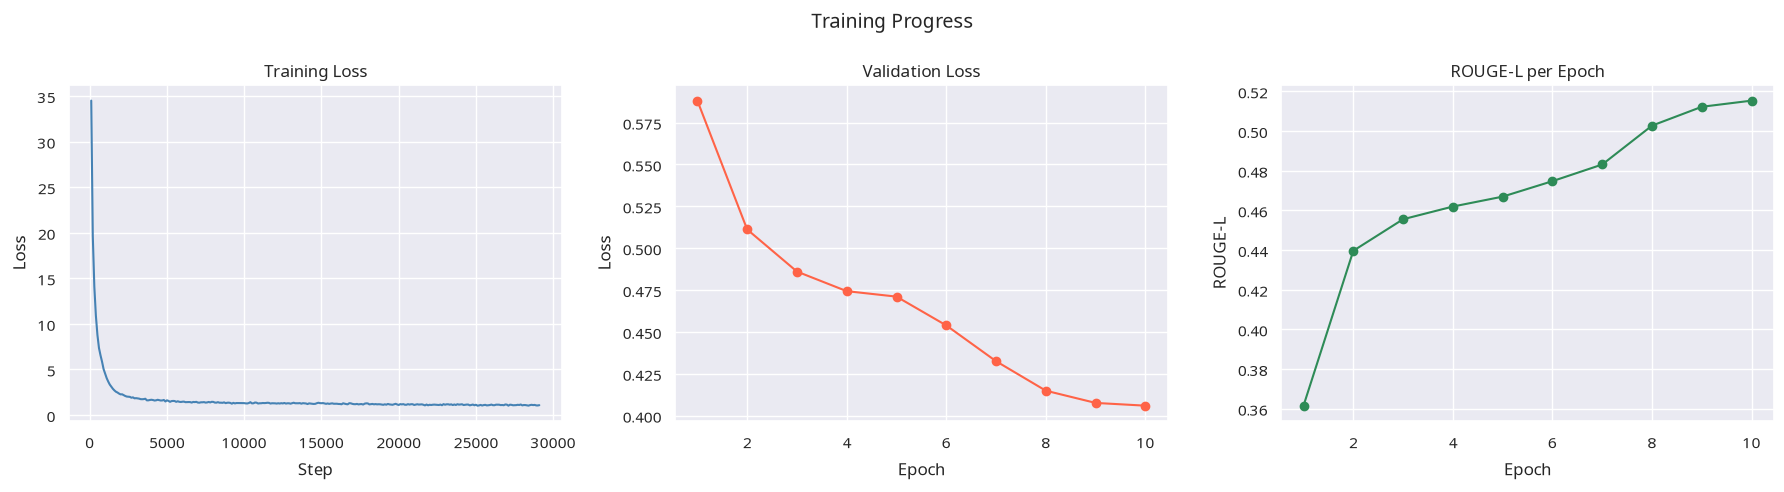

In [26]:
log_history = trainer.state.log_history
train_logs  = [x for x in log_history if 'loss' in x and 'eval_loss' not in x]
eval_logs   = [x for x in log_history if 'eval_loss' in x]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Training Progress', fontsize=14, fontweight='bold')

if train_logs:
    steps  = [x['step'] for x in train_logs]
    t_loss = [x['loss'] for x in train_logs]
    axes[0].plot(steps, t_loss, color='steelblue')
    axes[0].set_title('Training Loss')
    axes[0].set_xlabel('Step')
    axes[0].set_ylabel('Loss')

if eval_logs:
    epochs = [x.get('epoch', i+1) for i, x in enumerate(eval_logs)]
    e_loss = [x['eval_loss'] for x in eval_logs]
    axes[1].plot(epochs, e_loss, marker='o', color='tomato')
    axes[1].set_title('Validation Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')

if eval_logs and 'eval_rougeL' in eval_logs[0]:
    rougel = [x['eval_rougeL'] for x in eval_logs]
    axes[2].plot(epochs, rougel, marker='o', color='seagreen')
    axes[2].set_title('ROUGE-L per Epoch')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('ROUGE-L')

plt.tight_layout()
plt.savefig(f"{CONFIG['output_dir']}/training_progress.png", dpi=150, bbox_inches='tight')
plt.show()

## Section 10: Evaluation on Test Set — ROUGE, BLEU, BERTScore

In [27]:
model.eval()
predictions, references = [], []

EVAL_SAMPLE = min(CONFIG['eval_sample'], len(test_df))

for _, row in tqdm(test_df.head(EVAL_SAMPLE).iterrows(), total=EVAL_SAMPLE, desc='Evaluating'):
    inputs = tokenizer(
        row['model_input'],
        max_length=CONFIG['max_input_len'],
        truncation=True,
        return_tensors='pt'
    ).to(DEVICE)
    with torch.no_grad():
        ids = model.generate(
            **inputs,
            max_length=CONFIG['max_target_len'],
            num_beams=4,
            no_repeat_ngram_size=3,
            early_stopping=True
        )
    pred = tokenizer.decode(ids[0], skip_special_tokens=True)
    predictions.append(pred)
    references.append(row[CONFIG['summary_col']])

final_rouge = rouge.compute(predictions=predictions, references=references, tokenizer=bangla_tokenize)
print('── ROUGE Scores ─────────────────')
for k, v in final_rouge.items():
    print(f'  {k:12s}: {v:.4f}')

Evaluating: 100%|██████████| 500/500 [19:03<00:00,  2.29s/it]


── ROUGE Scores ─────────────────
  rouge1      : 0.4390
  rouge2      : 0.3227
  rougeL      : 0.4164
  rougeLsum   : 0.4163


In [28]:
smoother     = SmoothingFunction().method4
bleu1_scores = []
bleu4_scores = []

for pred, ref in tqdm(zip(predictions, references), total=len(predictions), desc='BLEU'):
    hyp  = list(pred.strip())
    refs = [list(ref.strip())]
    bleu1_scores.append(sentence_bleu(refs, hyp, weights=(1,0,0,0),        smoothing_function=smoother))
    bleu4_scores.append(sentence_bleu(refs, hyp, weights=(.25,.25,.25,.25), smoothing_function=smoother))

all_refs  = [[list(r.strip())] for r in references]
all_hyps  = [list(p.strip())   for p in predictions]
corpus_b1 = corpus_bleu(all_refs, all_hyps, weights=(1,0,0,0))
corpus_b4 = corpus_bleu(all_refs, all_hyps, weights=(.25,.25,.25,.25))

print('── BLEU Scores ───────────────────')
print(f'  Sentence BLEU-1 (mean): {np.mean(bleu1_scores):.4f}')
print(f'  Sentence BLEU-4 (mean): {np.mean(bleu4_scores):.4f}')
print(f'  Corpus   BLEU-1       : {corpus_b1:.4f}')
print(f'  Corpus   BLEU-4       : {corpus_b4:.4f}')

BLEU: 100%|██████████| 500/500 [00:01<00:00, 368.73it/s]


── BLEU Scores ───────────────────
  Sentence BLEU-1 (mean): 0.7628
  Sentence BLEU-4 (mean): 0.5573
  Corpus   BLEU-1       : 0.8103
  Corpus   BLEU-4       : 0.6080


In [29]:
P, R, F1 = bert_score(predictions, references, lang='bn', device=DEVICE)
bertscore_f1 = F1.mean().item()

print('── BERTScore ─────────────────────')
print(f'  Precision : {P.mean().item():.4f}')
print(f'  Recall    : {R.mean().item():.4f}')
print(f'  F1        : {bertscore_f1:.4f}')

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6862.00it/s]
[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


── BERTScore ─────────────────────
  Precision : 0.7750
  Recall    : 0.7922
  F1        : 0.7832


## Section 11: Results Visualization

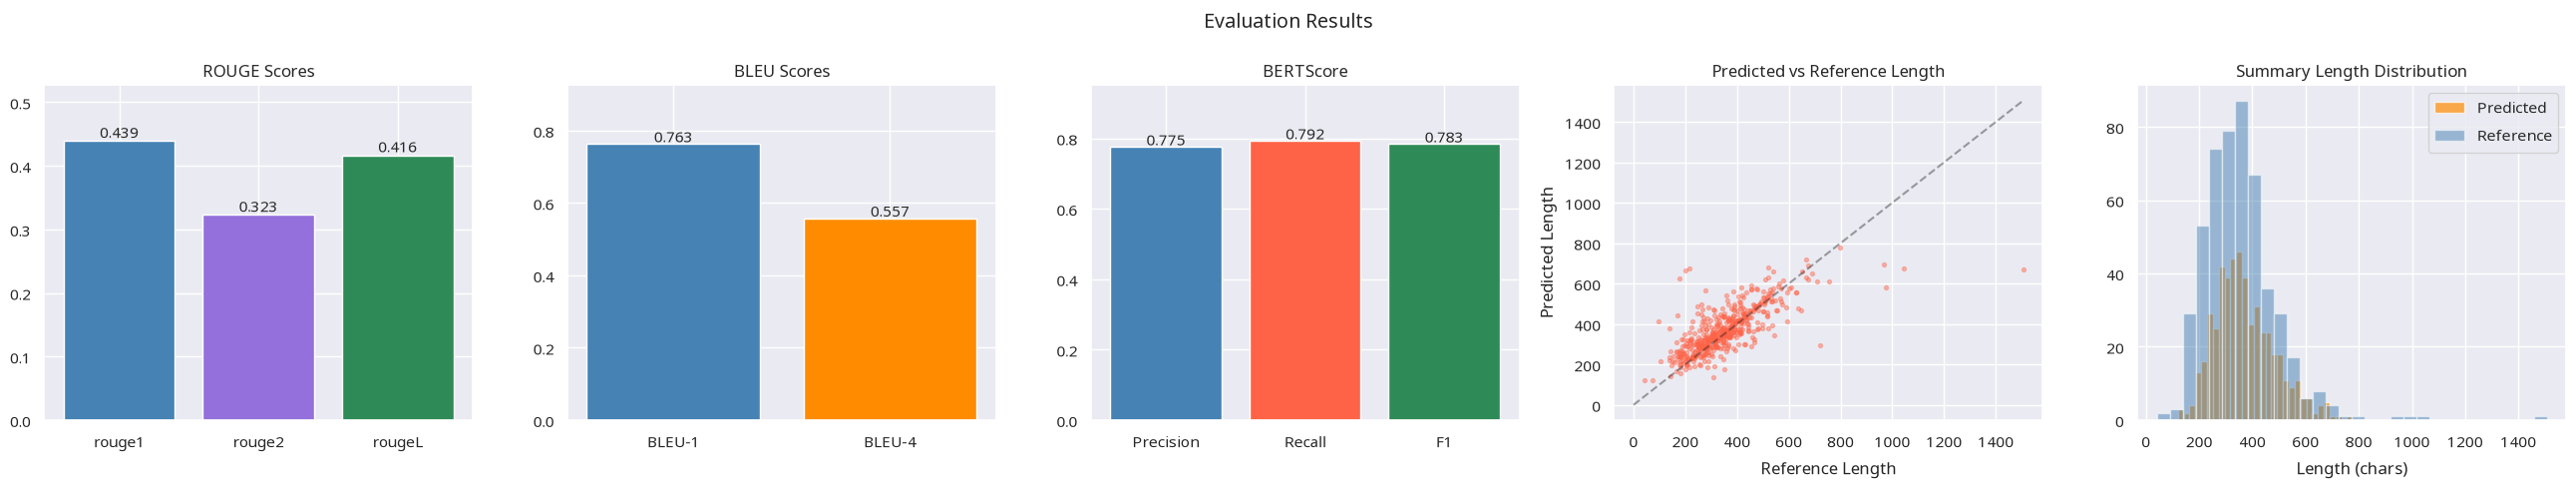

In [30]:
pred_lens = [len(p) for p in predictions]
ref_lens  = [len(r) for r in references]

fig, axes = plt.subplots(1, 5, figsize=(26, 5))
fig.suptitle('Evaluation Results', fontsize=14, fontweight='bold')

rouge_keys = ['rouge1', 'rouge2', 'rougeL']
rouge_vals = [final_rouge[k] for k in rouge_keys]
axes[0].bar(rouge_keys, rouge_vals, color=['steelblue','mediumpurple','seagreen'])
for i, v in enumerate(rouge_vals):
    axes[0].text(i, v + 0.005, f'{v:.3f}', ha='center', fontsize=11)
axes[0].set_title('ROUGE Scores')
axes[0].set_ylim(0, max(rouge_vals) * 1.2)

bleu_keys = ['BLEU-1', 'BLEU-4']
bleu_vals = [np.mean(bleu1_scores), np.mean(bleu4_scores)]
axes[1].bar(bleu_keys, bleu_vals, color=['steelblue','darkorange'])
for i, v in enumerate(bleu_vals):
    axes[1].text(i, v + 0.005, f'{v:.3f}', ha='center', fontsize=11)
axes[1].set_title('BLEU Scores')
axes[1].set_ylim(0, max(bleu_vals) * 1.2 + 0.01)

bs_vals   = [P.mean().item(), R.mean().item(), bertscore_f1]
bs_labels = ['Precision', 'Recall', 'F1']
axes[2].bar(bs_labels, bs_vals, color=['steelblue','tomato','seagreen'])
for i, v in enumerate(bs_vals):
    axes[2].text(i, v + 0.005, f'{v:.3f}', ha='center', fontsize=11)
axes[2].set_title('BERTScore')
axes[2].set_ylim(0, max(bs_vals) * 1.2)

axes[3].scatter(ref_lens, pred_lens, alpha=0.4, s=8, color='tomato')
axes[3].plot([0, max(ref_lens)], [0, max(ref_lens)], 'k--', alpha=0.4)
axes[3].set_xlabel('Reference Length')
axes[3].set_ylabel('Predicted Length')
axes[3].set_title('Predicted vs Reference Length')

axes[4].hist(pred_lens, bins=30, color='darkorange', edgecolor='white', label='Predicted', alpha=0.7)
axes[4].hist(ref_lens,  bins=30, color='steelblue',  edgecolor='white', label='Reference', alpha=0.5)
axes[4].set_title('Summary Length Distribution')
axes[4].set_xlabel('Length (chars)')
axes[4].legend()

plt.tight_layout()
plt.savefig(f"{CONFIG['output_dir']}/evaluation_results.png", dpi=150, bbox_inches='tight')
plt.show()

In [31]:
for i in range(3):
    print('=' * 70)
    print(f'Sample #{i+1}')
    print(f'INPUT    : {test_df.iloc[i]["model_input"][:200]}...')
    print(f'REFERENCE: {references[i]}')
    print(f'PREDICTED: {predictions[i]}')
    print()

Sample #1
INPUT    : সারসংক্ষেপ করুন [শিক্ষা]: প্রিয় শিক্ষার্থীরা বাংলা প্রথমপত্রের নদীর স্বপ্ন কবিতা থেকে সৃজনশীল প্রশ্নোত্তর আলোচনা করা হলো নদীর স্বপ্ন প্রশ্ন ১। নিচের উদ্দীপকটি পড় এবং প্রশ্নগুলোর উত্তর দাও নুরু, শাফি, ...
REFERENCE: উদ্দীপকের নুরু, শফি, আয়েশা, রেহানা তাদের কৈশোরের দুরন্তপনায় অজানায় হারানের স্বপ্নকে সার্থক করে তুলেছে। দিঘির পাড়ে জমিয়ে রান্নাবান্না করে তারা তাদের দুরন্তপনার বাস্তব জীবনে হারিয়ে গেছে। উদ্দীপকের আবেগের প্রকাশ ঘটেছে পিকনিকের আয়োজনে আর নদীর স্বপ্ন কবিতায় নদী ভ্রমণের কল্পনার ভুবনে হারিয়ে গিয়ে।
PREDICTED: এদিকে বলতে গেলে তাদের সবটুকু সম্বলই কানাই নৌকা ভ্রমণের বিনিময়ে মাঝিকে দিতে চায়। এদিক থেকে উদ্দীপকের সাথে কবিতার অমিল লক্ষ করা যায়। এদিকে আসতে চাইলে তারা দিঘির জলে দাপাদাপি শেষে কলাপাতায় রান্না করা খিচুড়ি খেয়েছে।

Sample #2
INPUT    : সারসংক্ষেপ করুন [প্রজন্ম]: বাংলা সাহিত্যে ও বাঙালি মননে কাজী নজরুল ইসলাম ১৮৯৯১৯৭৬ স্বতন্ত্র মর্যাদায় চিহ্নিত হয়ে আছেন। তিনি একাধারে সামাজিক, সাংস্কৃতিক ও রাজনৈতিক নবজাগরণের বাণীবাহক। রবীন্দ্রযুগে যে ক...
REFERENCE: রবীন্দ

## Section 12: Save Model

In [32]:
save_dir = CONFIG['model_save_dir']

for param in model.parameters():
    if not param.is_contiguous():
        param.data = param.data.contiguous()

model.save_pretrained(save_dir)
tokenizer.save_pretrained(save_dir)

scores = {
    'rouge'     : final_rouge,
    'bleu'      : {
        'sentence_bleu1': float(np.mean(bleu1_scores)),
        'sentence_bleu4': float(np.mean(bleu4_scores)),
        'corpus_bleu1'  : float(corpus_b1),
        'corpus_bleu4'  : float(corpus_b4),
    },
    'bertscore' : {'precision': P.mean().item(), 'recall': R.mean().item(), 'f1': bertscore_f1}
}
with open(os.path.join(save_dir, 'eval_scores.json'), 'w') as f:
    json.dump(scores, f, indent=2)

print(f'Model saved to: {save_dir}')
print('Files:')
for f in os.listdir(save_dir):
    print(f'  - {f}')

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.02it/s]

Model saved to: ./fine_tuned_banglat5
Files:
  - config.json
  - eval_scores.json
  - generation_config.json
  - model.safetensors
  - tokenizer.json
  - tokenizer_config.json
